### Libraries

In [75]:
import json
import numpy as np
import pandas as pd
from datetime import datetime
import folium
import math
from scipy.interpolate import CubicSpline
import matplotlib.pyplot as plt
import overpy
from geopy.distance import geodesic
from geopy import Point
import requests
from shapely.geometry import Point, Polygon, LineString
from shapely.ops import substring, nearest_points
from IPython.display import display
from shapely.geometry import LineString, MultiLineString
from shapely.ops import transform
from shapely.geometry import JOIN_STYLE
from pyproj import Transformer

### Load Line of Sight

In [76]:
# ---------------- CONFIG ----------------
POLYGONS_JSON   = "polygons.json"            # {"polygon_1":[[lon,lat],...], ... "polygon_5":[...]}
PORTLINES_JSON  = "portlines.json"           # {"portline_1":[[lon,lat],...], ..., "portline_6":[...]}
RHEINHAFEN_CENTERLINE_JSON = "Rheinhafen_line_of_sight.json"   # [[lat,lon], ...]  (already lat,lon)
CUXHAVEN_CENTERLINE_JSON = "Cuxhaven_line_of_sight.json"  # [[lat,lon], ...] (already lat,lon)


# small numeric tolerances
ON_LINE_TOL = 2e-4     # ~20 m for "on the line" tests
LAT_EPS     = 1e-6     # latitude stop tolerance (~0.1 m)
# ---------------------------------------


# ---------- helpers ----------



# ---------- load data ----------
with open(POLYGONS_JSON, "r", encoding="utf-8") as f:
    polys_lonlat = json.load(f)     # [lon,lat]
with open(PORTLINES_JSON, "r", encoding="utf-8") as f:
    ports_latlon = json.load(f)     # [lon,lat]
with open(RHEINHAFEN_CENTERLINE_JSON, "r", encoding="utf-8") as f:
    Rheinhafen_centerline_latlon = json.load(f)  # [lat,lon]
with open(CUXHAVEN_CENTERLINE_JSON, "r", encoding="utf-8") as f:
    Cuxhaven_centerline_latlon = json.load(f)  # [lat,lon]




### Helper function for line of sight

In [77]:
def latlon_to_linestring(seq_latlon):
    """Convert [[lat,lon], ...] to shapely LineString (x=lon, y=lat)."""
    return LineString([(lon, lat) for (lat, lon) in seq_latlon])

def nearest_point_on_line(seq_latlon, ref_latlon):
    """Nearest point on a polyline (returned as [lat,lon])."""
    line = latlon_to_linestring(seq_latlon)
    p = Point(ref_latlon[1], ref_latlon[0])
    np = nearest_points(line, p)[0]
    return (np.y, np.x)

def segment_along_line(seq_latlon, a_latlon, b_latlon):
    """
    Forward-only subline from a to b (projections along the polyline),
    includes exact endpoints, de-duplicates.
    """
    line = latlon_to_linestring(seq_latlon)
    a_d  = line.project(Point(a_latlon[1], a_latlon[0]))
    b_d  = line.project(Point(b_latlon[1], b_latlon[0]))
    if a_d <= b_d:
        seg = substring(line, a_d, b_d)
    else:
        seg = substring(line, b_d, a_d)
        seg = LineString(list(seg.coords)[::-1])

    coords = [(y, x) for (x, y) in seg.coords]
    if not coords or coords[0] != a_latlon: coords = [a_latlon] + coords
    if not coords or coords[-1] != b_latlon: coords = coords + [b_latlon]
    out = []
    for p in coords:
        if not out or p != out[-1]:
            out.append(p)
    return out

def pick_prev_centerline_vertex(centerline_latlon, join_latlon, end_latlon):
    """
    Return the 'previous' centerline vertex relative to motion from join→END,
    guaranteeing we pick an interior vertex (not the endpoint).
    """
    cl_line = latlon_to_linestring(centerline_latlon)
    L = cl_line.length
    dj = cl_line.project(Point(join_latlon[1], join_latlon[0]))
    de = cl_line.project(Point(end_latlon[1],  end_latlon[0]))

    # keep de strictly inside (avoid snapping to endpoints)
    eps = 1e-9 * L if L > 0 else 0.0
    if de <= eps:     de = min(eps*10, L/1000.0)
    if de >= L - eps: de = max(L - eps*10, L - L/1000.0)

    forward = de >= dj
    cl_dists = [cl_line.project(Point(pt[1], pt[0])) for pt in centerline_latlon]

    prev_idx = None
    for i in range(len(cl_dists) - 1):
        a, b = cl_dists[i], cl_dists[i+1]
        if a <= de <= b:
            prev_idx = i if forward else i+1
            break
        if b <= de <= a:
            prev_idx = i+1 if forward else i
            break

    if prev_idx is None:
        prev_idx = len(centerline_latlon) - 2 if forward else 1
    return centerline_latlon[prev_idx]

def splice_pl6_to_centerline(pl6_latlon, centerline_latlon, join_on_pl6):
    """
    Find a good splice between portline_6 and the centerline.
    Prefer true intersections; otherwise use nearest points between the two polylines.
    Returns (p6_splice_latlon, cl_splice_latlon).
    """
    pl6_line = latlon_to_linestring(pl6_latlon)
    cl_line  = latlon_to_linestring(centerline_latlon)
    inter    = pl6_line.intersection(cl_line)
    join_d   = pl6_line.project(Point(join_on_pl6[1], join_on_pl6[0]))

    candidates_on_pl6 = []

    def add_candidate(pt):
        if pt.is_empty: return
        if isinstance(pt, Point):
            candidates_on_pl6.append((pt.y, pt.x))
        elif hasattr(pt, "geoms"):  # MultiPoint/GeometryCollection
            for g in pt.geoms:
                add_candidate(g)
        elif isinstance(pt, LineString):
            coords = list(pt.coords)
            if coords:
                candidates_on_pl6.append((coords[0][1], coords[0][0]))
                candidates_on_pl6.append((coords[-1][1], coords[-1][0]))

    add_candidate(inter)

    if candidates_on_pl6:
        # first intersection reached when moving along pl6 from the join
        def forward_dist(latlon):
            d = pl6_line.project(Point(latlon[1], latlon[0]))
            return d - join_d if d >= join_d else float("inf")
        p6_splice = min(candidates_on_pl6, key=forward_dist)
        if forward_dist(p6_splice) == float("inf"):
            q6, qc = nearest_points(pl6_line, cl_line)
            return (q6.y, q6.x), (qc.y, qc.x)
        qc = nearest_points(cl_line, Point(p6_splice[1], p6_splice[0]))[0]
        return p6_splice, (qc.y, qc.x)
    else:
        q6, qc = nearest_points(pl6_line, cl_line)
        return (q6.y, q6.x), (qc.y, qc.x)

def trim_centerline_by_end_lat(seg_latlon, end_lat):
    """
    Given a centerline segment seg_latlon ([lat,lon] from start→end),
    stop BEFORE we pass END's latitude. Used only when finishing via centerline.
    """
    if not seg_latlon:
        return seg_latlon

    lat0, lat1 = seg_latlon[0][0], seg_latlon[-1][0]
    lat_increasing = (lat1 >= lat0)

    out = []
    for pt in seg_latlon:
        lat = pt[0]
        passed = (lat_increasing and lat >  end_lat + LAT_EPS) or \
                 (not lat_increasing and lat < end_lat - LAT_EPS)
        out.append(pt)
        if passed:
            out.pop()  # drop the point that crossed the latitude
            break
        if abs(lat - end_lat) <= LAT_EPS:
            break

    if not out:
        out = [seg_latlon[0]]
    return out

def lineofsightnopolygon(START_LATLON, END_LATLON, centerline_latlon):
    """
    Build a line of sight from START to END without considering polygons.
    Uses the centerline as the main route.
    """

    initial_x = START_LATLON[0]
    initial_y = START_LATLON[1]
    final_x = END_LATLON[0]
    final_y = END_LATLON[1]
    use_reverse = (final_x - initial_x) < 0
    
    x_min = min(initial_x, final_x)
    x_max = max(initial_x, final_x)

    simulation_path = [START_LATLON]
    if use_reverse:
        print("yes, reverse")
        centerline_latlon = centerline_latlon[::-1]
    
    simulation_path.extend(
        [pt for pt in centerline_latlon
         if x_min <= pt[0] <= x_max]
    )
    simulation_path.append(END_LATLON)
    return simulation_path

def lineofsight(START_LATLON, END_LATLON,polys_lonlat, ports_latlon, centerline_latlon):
    # ---------- choose portline_N from START polygon ----------
    p_start = Point(START_LATLON[1], START_LATLON[0])
    containing, nearest_name, nearest_d = None, None, float("inf")
    for name in sorted(polys_lonlat.keys(), key=lambda k: int(k.split("_")[-1])):
        poly = Polygon(polys_lonlat[name])  # still [lon,lat]
        if poly.contains(p_start) or poly.touches(p_start):
            containing = name
            break
    if containing is None:
        route_filtered = lineofsightnopolygon(START_LATLON, END_LATLON,centerline_latlon)
    else:
        N = int(containing.split("_")[-1])
        print(f"Start is in/near: {containing}  → using portline_{N}")

        # ---------- START → along portline_N to its junction with portline_6 ----------
        plN = ports_latlon[f"portline_{N}"]
        pl6 = ports_latlon["portline_6"]
        if not plN or not pl6:
            raise RuntimeError("Missing portline_N or portline_6")

        # choose plN endpoint closer to pl6 as the junction end
        pl6_line = latlon_to_linestring(pl6)
        endA, endB = plN[0], plN[-1]
        junc_end = endA if pl6_line.distance(Point(endA[1], endA[0])) <= pl6_line.distance(Point(endB[1], endB[0])) else endB

        start_on_plN = nearest_point_on_line(plN, START_LATLON)
        plN_segment   = segment_along_line(plN, start_on_plN, junc_end)
        plN_segment.remove(plN_segment[0])  # remove the first point (START_LATLON)
        
        
        

        # exact join point on pl6
        join_on_pl6   = nearest_point_on_line(pl6, junc_end)

        # ---------- along portline_6 to a good splice with the centerline ----------
        p6_splice, cl_splice = splice_pl6_to_centerline(pl6, centerline_latlon, join_on_pl6)
        pl6_leg = segment_along_line(pl6, join_on_pl6, p6_splice)

        # ---------- centerline to the 'previous' vertex, trimmed by END latitude, then straight to END ----------
        prev_point = pick_prev_centerline_vertex(centerline_latlon, cl_splice, END_LATLON)
        cl_leg     = segment_along_line(centerline_latlon, cl_splice, prev_point)
        cl_leg     = trim_centerline_by_end_lat(cl_leg, END_LATLON[0])  # << trim-by-lat rule

        last_on_cl = cl_leg[-1] if cl_leg else cl_splice
        final_leg  = [last_on_cl, END_LATLON]

        # ---------- assemble final route ----------
        route_unfiltered = [START_LATLON] + plN_segment + pl6_leg[1:] + cl_leg[1:] + final_leg
        route_filtered = [pt for pt in route_unfiltered if pt[1] <= START_LATLON[1]]
    return route_filtered

def point_in_port_polygons(latlon, polys_lonlat):
    """Return (True, name) if (lat,lon) is inside/touching any polygon; else (False, None)."""
    p = Point(latlon[1], latlon[0])  # shapely Point(lon,lat)
    for name, coords_lonlat in polys_lonlat.items():
        poly = Polygon(coords_lonlat)
        if poly.contains(p) or poly.touches(p):
            return True, name
    return False, None

def _nearest_end_towards_pl6(plN_latlon, pl6_latlon):
    """Pick the endpoint of plN that's closer to pl6 (junction end)."""
    pl6_line = latlon_to_linestring(pl6_latlon)
    endA, endB = plN_latlon[0], plN_latlon[-1]
    dA = pl6_line.distance(Point(endA[1], endA[0]))
    dB = pl6_line.distance(Point(endB[1], endB[0]))
    return endA if dA <= dB else endB

def dedup_consecutive(seq, ndp=5, truncate=False):
    """
    Collapse consecutive duplicate coordinates after reducing precision.

    seq: list of (lat, lon)
    ndp: number of decimal places (default 5)
    truncate: if True, truncate instead of round
    """
    if not seq:
        return []

    def clip(pt):
        if truncate:
            m = 10 ** ndp
            return (math.trunc(pt[0] * m) / m, math.trunc(pt[1] * m) / m)
        else:
            return (round(pt[0], ndp), round(pt[1], ndp))

    out = [clip(seq[0])]
    last = out[0]
    for x in seq[1:]:
        cx = clip(x)
        if cx != last:
            out.append(cx)
            last = cx
    return out

def build_route_port_to_port(START_LATLON, END_LATLON, polys_lonlat, ports_latlon):
    """Route entirely within the port network when both points are in polygons."""
    start_in, start_name = point_in_port_polygons(START_LATLON, polys_lonlat)
    end_in,   end_name   = point_in_port_polygons(END_LATLON,   polys_lonlat)
    print(f"Both points in polygons: START in {start_name}, END in {end_name}")
    if not (start_in and end_in):
        raise ValueError("Both START and END must be in polygons for port-to-port routing")
    

    N = int(start_name.split("_")[-1])  # polygon_N -> N
    M = int(end_name.split("_")[-1])

    pl6 = ports_latlon["portline_6"]
    pl6_reverse = pl6[::-1]

    if N == M:
        # Same polygon: just move along portline_N
        plN = ports_latlon[f"portline_{N}"]
        start_on = nearest_point_on_line(plN, START_LATLON)
        end_on   = nearest_point_on_line(plN, END_LATLON)
        segN     = segment_along_line(plN, start_on, end_on)
        route    = [START_LATLON] + segN[1:-1] + [END_LATLON]
        return dedup_consecutive(route)
    


    # Different polygons: plN -> pl6 -> plM
    plN = ports_latlon[f"portline_{N}"]
    plM = ports_latlon[f"portline_{M}"]

    # project START and END to their lines
    start_on_plN = nearest_point_on_line(plN, START_LATLON)
    end_on_plM   = nearest_point_on_line(plM, END_LATLON)

    # choose the ends that connect to pl6
    junc_N = _nearest_end_towards_pl6(plN, pl6)
    junc_M = _nearest_end_towards_pl6(plM, pl6)

    # travel along plN to pl6
    segN = segment_along_line(plN, start_on_plN, junc_N)

    # along pl6 between the two junctions (correct direction handled by segment_along_line)
    join_on_pl6_from_N = nearest_point_on_line(pl6, junc_N)
    join_on_pl6_to_M   = nearest_point_on_line(pl6, junc_M)
    seg6 = segment_along_line(pl6, join_on_pl6_from_N, join_on_pl6_to_M)

    # from pl6 into plM to END
    segM = segment_along_line(plM, junc_M, end_on_plM)

    if start_name == "polygon_6":
        seg6_unfiltered = segment_along_line(pl6, join_on_pl6_from_N, join_on_pl6_to_M)
        if END_LATLON[1] > START_LATLON[1]:
            seg6 = [pt for pt in pl6_reverse if pt[1] >= START_LATLON[1]]
        else:       
            seg6 = [pt for pt in pl6 if pt[1] <= START_LATLON[1]]
        return dedup_consecutive([START_LATLON] + seg6[1:] + segM[1:-1] + [END_LATLON])
    
    if end_name == "polygon_6":
        seg6_unfiltered = segment_along_line(pl6, join_on_pl6_from_N, join_on_pl6_to_M)
        if END_LATLON[1] > START_LATLON[1]:
            seg6 = [pt for pt in pl6_reverse if pt[1] <= END_LATLON[1]]
        else:
            seg6 = [pt for pt in pl6 if pt[1] >= END_LATLON[1]]
        return dedup_consecutive([START_LATLON] + segN[1:] + seg6[1:] + [END_LATLON])
    
    if (start_name == "polygon_1" or start_name == "polygon_2" or start_name == "polygon_3") and (end_name == "polygon_1" or end_name == "polygon_2" or end_name == "polygon_3"):
        
        return dedup_consecutive([START_LATLON] + segN[1:] + segM[1:-1] + [END_LATLON])

    
        
    
    
    print("lat point",segM[-1][1])

    # assemble (avoid duplicating touching points)
    route = [START_LATLON] + segN[1:] + seg6[1:] + segM[1:-1] + [END_LATLON]
    return dedup_consecutive(route)

def build_route_port_aware_Rhein(START_LATLON, END_LATLON,
                           polys_lonlat, ports_latlon, centerline_latlon):
    start_in, _ = point_in_port_polygons(START_LATLON, polys_lonlat)
    end_in,   _ = point_in_port_polygons(END_LATLON,   polys_lonlat)

    # NEW: if both inside → stay on the port network only
    if start_in and end_in:
        return build_route_port_to_port(START_LATLON, END_LATLON, polys_lonlat, ports_latlon)

    # If end is inside a port polygon (and start is not), flip S/E temporarily
    flipped = end_in and not start_in
    A, B = (END_LATLON, START_LATLON) if flipped else (START_LATLON, END_LATLON)

    # Build the line of sight in the forward direction
    route = lineofsight(A, B, polys_lonlat, ports_latlon, centerline_latlon)

    # Reverse back if we flipped
    if flipped:
        route = route[::-1]
        route = dedup_consecutive(route)

    return route

def offset_polyline_latlon(seq_latlon, offset_m=30.0, side="left"):
    """
    Offset a [lat,lon] polyline by `offset_m` meters to the 'left' or 'right'
    (left/right is with respect to the vertex order). Returns a [lat,lon] list.
    """
    # 1) Build LineString in (lon, lat) order for Shapely
    line_ll = LineString([(lon, lat) for (lat, lon) in seq_latlon])

    # 2) Choose a metric CRS (UTM32N for ~8E, 49N)
    #    If you want automatic zone selection, compute from mean lon.
    transformer_fwd = Transformer.from_crs("EPSG:4326", "EPSG:32632", always_xy=True)
    transformer_inv = Transformer.from_crs("EPSG:32632", "EPSG:4326", always_xy=True)

    to_utm   = lambda x, y, z=None: transformer_fwd.transform(x, y)
    to_wgs84 = lambda x, y, z=None: transformer_inv.transform(x, y)

    # 3) Project to meters, offset, and pick the longest piece if it splits
    line_xy = transform(to_utm, line_ll)
    off = line_xy.parallel_offset(
        distance=offset_m,
        side=side,                   # 'left' or 'right'
        join_style=JOIN_STYLE.round, # smoother corners; try .mitre or .bevel if you prefer
        resolution=16                # higher = smoother arcs around bends
    )

    if isinstance(off, MultiLineString):
        # pick the longest piece to preserve the main shape
        off = max(off.geoms, key=lambda g: g.length)

    # 4) Back to WGS84 and return as [lat,lon]
    off_ll = transform(to_wgs84, off)
    return [(lat, lon) for (lon, lat) in off_ll.coords]

def lineofsight_Cuxhaven(START_LATLON, END_LATLON, centerline_latlon):
    """
    Build a line of sight from START to END without considering polygons.
    Uses the centerline as the main route.
    """

    initial_x = START_LATLON[0]
    initial_y = START_LATLON[1]
    final_x = END_LATLON[0]
    final_y = END_LATLON[1]
    use_reverse = (final_y - initial_y) > 0
    print(final_y-initial_y)
    print(use_reverse)

    y_min = min(initial_y, final_y)
    y_max = max(initial_y, final_y)

    simulation_path = [START_LATLON]
    if use_reverse:
        print("yes, reverse")
        centerline_latlon = centerline_latlon[::-1]
    
    simulation_path.extend(
        [pt for pt in centerline_latlon
         if y_min <= pt[1] <= y_max]
    )
    simulation_path.append(END_LATLON)
    return dedup_consecutive(simulation_path)

def latlon_to_xy(lat, lon):
        R = 6371000
        x = math.radians(lon) * R * math.cos(math.radians(lat))
        y = math.radians(lat) * R
        return x, y

def signed_cte_to_segment(point_latlon, seg_a_latlon, seg_b_latlon):
    """
    Cross-track error (meters) from point to the infinite line through seg_a->seg_b,
    with sign from the 2D cross product (left/right of segment direction).
    Uses your latlon_to_xy() planar helper.
    """
    px, py = latlon_to_xy(point_latlon[0], point_latlon[1])
    x1, y1 = latlon_to_xy(seg_a_latlon[0], seg_a_latlon[1])
    x2, y2 = latlon_to_xy(seg_b_latlon[0], seg_b_latlon[1])

    dx, dy = x2 - x1, y2 - y1
    if dx == 0 and dy == 0:
        return 0.0

    # projection of P onto the (infinite) line AB
    u = ((px - x1) * dx + (py - y1) * dy) / (dx*dx + dy*dy)
    proj_x = x1 + u * dx
    proj_y = y1 + u * dy

    cte = math.hypot(px - proj_x, py - proj_y)
    cross = (x2 - x1) * (py - y1) - (y2 - y1) * (px - x1)
    return float(np.sign(cross)) * cte

def first_cte(start_latlon, simulation_path):
    """
    Your 'first CTE' at step 0:
    distance from START to the segment simulation_path[1] -> simulation_path[2].
    """
    if len(simulation_path) < 3:
        raise ValueError("simulation_path must have at least 3 points")
    p1 = simulation_path[1]
    p2 = simulation_path[2]
    return signed_cte_to_segment(start_latlon, p1, p2)

### Load the parameters

In [78]:
class ShipParameters:
    def __init__(self, initial_x, initial_y, heading_deg):
        # Physical constants
        self.rho_water = 1000  # kg/m³

        # Propeller parameters
        self.D = 3.0            # diameter [m]
        self.KT = 0.3           # thrust coefficient
        self.target_n_rpm = 180  # target rpm
        self.n_rpm = 0         # start from 0
        self.n = 0.0             # rev/s, will update during simulation

        # Rudder parameters
        self.AR = 15            # area [m²]
        self.CL = 0.8           # lift coefficient
        self.CD_rudder = 0.02   # drag coefficient
        self.delta_deg = 0    # rudder angle in degrees
        self.delta = np.radians(self.delta_deg)

        # Initial state
        self.u = 2.0            # surge velocity
        self.v = 0.0            # sway velocity
        self.r = 0.0            # yaw rate

        self.x = initial_x      # user input
        self.y = initial_y
        self.psi = np.radians(heading_deg)

        # Ship parameters
        self.mass = 6_500_000   # kg
        self.Iz = 4e8           # yaw moment of inertia
        self.xR = 60.0          # rudder distance from CG [m]

        # Drag
        self.S = 4000           # wetted surface [m²]
        self.CD = 0.002         # hull drag coeff

        self.tp = 0.15          # Thrust deduction factor
        self.w = 0.15           # Wake fraction


        # Simulation
        self.dt = 1           # time step [s]


### Calculate the forces

In [79]:
def calculate_J(params):
    denom = params.n * params.D
    if denom == 0:
        return 0.0  # Prevent divide by zero
    J = params.u * (1 - params.w) / denom
    return min(J, 5.0)  # clamp extreme cases


def KT_of_J(J):
    # Example quadratic fit
    a, b, c = 1.333, -0.8, -0.0667
    KT = a * J**2 + b * J + c
    if np.isnan(KT) or np.isinf(KT):
        return 0.0
    return max(0.1, min(KT, 0.4))  # clamp to realistic range


def calculate_propeller_force(params):
    J = calculate_J(params)
    KT = KT_of_J(J)
    TP = params.rho_water * params.n**2 * params.D**4 * KT
    XP = (1 - params.tp) * TP  # Surge contribution
    return XP

def calculate_drag_force(params):
    return 0.5 * params.rho_water * params.S * params.CD * params.u**2

def CL_of_delta(delta_rad):
    CL_slope = 6.0  # Lift slope (per radian)
    return CL_slope * delta_rad

def CD_of_delta(delta_rad):
    CD0 = 0.02
    k = 2.5
    return CD0 + k * delta_rad**2

def calculate_rudder_forces(params):
    params.delta = np.clip(params.delta, -np.radians(35), np.radians(35))

    UR = params.u
    delta = params.delta

    CL = CL_of_delta(delta)
    CD_rudder = CD_of_delta(delta)

    LR = 0.5 * params.rho_water * params.AR * UR**2 * CL
    DR = 0.5 * params.rho_water * params.AR * UR**2 * CD_rudder

    XR = -DR * np.cos(delta) + LR * np.sin(delta)
    YR = -DR * np.sin(delta) - LR * np.cos(delta)
    NR = YR * params.xR

    return XR, YR, NR

def calculate_wind_forces(params, vw, theta_w):
    """
    vw: wind speed (m/s)
    theta_w: wind direction FROM which wind is coming (degrees from North)
    """
    # Convert wind direction to radians and to direction TO which wind is going
    theta_w_rad = np.radians((theta_w + 180) % 360)

    # Project wind velocity onto ship axes
    uw = vw * np.cos(theta_w_rad - params.psi)
    vw_side = vw * np.sin(theta_w_rad - params.psi)

    # Coefficients (tune if needed)
    A_surge = 75  # frontal wind area
    A_sway = 225  # side wind area
    CD_wind = 0.6  # wind drag coefficient
    rho_air = 1.225  # kg/m³

    # Surge and sway wind forces (Xw and Yw)
    Xw = 0.5 * rho_air * CD_wind * A_surge * uw * abs(uw)
    Yw = 0.5 * rho_air * CD_wind * A_sway * vw_side * abs(vw_side)
    Nw = Yw * params.xR * 0.3  # Wind moment - simplified

    return Xw, Yw, Nw

def calculate_current_forces(params, Uc, theta_c):
    """
    Uc: current speed (m/s)
    theta_c: direction FROM which current is coming (° from North)
    """
    # Convert to direction TO which current is going
    theta_c_rad = np.radians((theta_c + 180) % 360)

    # Relative velocity of current in ship's frame
    uc_surge = Uc * np.cos(theta_c_rad - params.psi)
    uc_sway = Uc * np.sin(theta_c_rad - params.psi)

    # Parameters (tune if needed)
    A_surge_c = 25     # frontal underwater area
    A_sway_c = 75     # side underwater area
    CD_current = 0.6
    rho_water = params.rho_water

    # Current-induced forces (modeled similar to drag)
    Xc = 0.5 * rho_water * CD_current * A_surge_c * uc_surge * abs(uc_surge)
    Yc = 0.5 * rho_water * CD_current * A_sway_c * uc_sway * abs(uc_sway)
    Nc = Yc * params.xR * 0.3  # Simplified yaw moment

    return Xc, Yc, Nc


### Calculating the heading

In [80]:
def calculate_bearing(pointA, pointB):
    """
    Returns bearing from pointA to pointB (in degrees)
    """
    lat1, lon1 = map(math.radians, pointA)
    lat2, lon2 = map(math.radians, pointB)

    d_lon = lon2 - lon1

    x = math.sin(d_lon) * math.cos(lat2)
    y = math.cos(lat1)*math.sin(lat2) - math.sin(lat1)*math.cos(lat2)*math.cos(d_lon)

    bearing = math.atan2(x, y)
    return (math.degrees(bearing) + 360) % 360

# REPLACE your get_wind_data() with this
def get_wind_data(lat, lon, api_key, _cache={"t": -1, "val": (0.0, 0.0)}):
    """
    Returns (wind_speed m/s, wind_direction deg FROM North).
    Caches the last successful value and falls back if the API call fails.
    """
    url = "http://api.openweathermap.org/data/2.5/weather"
    params = {'lat': lat, 'lon': lon, 'appid': api_key, 'units': 'metric'}

    try:
        resp = requests.get(url, params=params, timeout=5)
        resp.raise_for_status()
        data = resp.json()
        w = data.get('wind', {})
        speed = float(w.get('speed', 0.0))
        direction = float(w.get('deg', 0.0))
        _cache["val"] = (speed, direction)
        return _cache["val"]
    except Exception:
        # Fallback to last known value (or calm)
        return _cache["val"]


### Simulation

In [81]:
def simulate_motion(params, simulation_path, final_x, final_y):
    # Control parameters
    k = 5                      # Lower k → more aggressive rudder response
    max_rudder_deg = 35
    ramp_duration_sec = 60
    cte_gain = 2               # Increased to strengthen lateral correction
    cte_switch_threshold = 10  # Require small CTE before switching waypoint
    dt = params.dt
    

    # Tracking
    x_hist, y_hist = [params.x], [params.y]
    cte_hist = []
    ref_idx = 1
    current_ref = simulation_path[ref_idx]
    last_pos = (params.x, params.y)
    log_data = {}  # step-indexed dictionary


    # Wind data (optional, can be replaced with actual API call)
    api_key = "6c77c4bd0f7280bf206a277dc5407cab"
    vw, theta_w = get_wind_data(params.x, params.y, api_key)  # wind speed & direction in degrees

    final_point = [final_x, final_y]
    max_steps = 20000  # Safety cap
    step = 0

    while True:
        time_elapsed_sec = step * dt

        # Update wind data every 5 minutes
        if step % 300 == 0:  # Every 5 minutes (if dt=1s)
            vw, theta_w = get_wind_data(params.x, params.y, api_key)


        # Termination condition: within 5 meters of final point
        
        distance_to_goal = geodesic((params.x, params.y), final_point).meters
        if distance_to_goal < 30:
            print(f"Reached goal within 5m at step {step}, time {time_elapsed_sec:.1f}s")
            break

        if step >= max_steps:
            print("Max step limit reached.")
            break

        step += 1

        # Propeller ramp-up
        if time_elapsed_sec <= ramp_duration_sec:
            target_n_rpm = (params.target_n_rpm * time_elapsed_sec) / ramp_duration_sec
        else:
            target_n_rpm = params.target_n_rpm
        if time_elapsed_sec == int(time_elapsed_sec):
            # Heading error
            current_pos = (params.x, params.y)
            bearing = calculate_bearing(current_pos, current_ref)
            required_heading = (90-bearing) % 360
            current_heading = np.degrees(params.psi) % 360

            heading_error = required_heading - current_heading
            if heading_error > 180:
                heading_error -= 360
            elif heading_error < -180:
                heading_error += 360

            # Cross-track error
            if ref_idx + 1 < len(simulation_path):
                p1 = simulation_path[ref_idx-1]
                p2 = simulation_path[ref_idx]
            else:
                p1 = simulation_path[ref_idx - 1]
                p2 = simulation_path[ref_idx]

            px, py = latlon_to_xy(params.x, params.y)
            x1, y1 = latlon_to_xy(p1[0], p1[1])
            x2, y2 = latlon_to_xy(p2[0], p2[1])

            dx, dy = x2 - x1, y2 - y1
            if dx == 0 and dy == 0:
                cte = 0
            else:
                u = ((px - x1) * dx + (py - y1) * dy) / (dx * dx + dy * dy)
                proj_x = x1 + u * dx
                proj_y = y1 + u * dy
                cte = ((px - proj_x)**2 + (py - proj_y)**2)**0.5
                cross = (x2 - x1)*(py - y1) - (y2 - y1)*(px - x1)
                cte *= np.sign(cross)

            cte_hist.append(cte)

            # Rudder control
            cte_effective = cte / max(1.0, params.u)  # scaled for speed
            rudder_angle = (-heading_error + cte_gain * cte_effective) / k

            rudder_angle = np.clip(rudder_angle, -max_rudder_deg, max_rudder_deg)
            dynamic_limit = np.clip(7 + (12 / max(params.u, 0.1)), 7, 35)
            rudder_angle = np.clip(rudder_angle, -dynamic_limit, dynamic_limit)

            # Thrust scaling
            thrust_factor = 0.5 if abs(rudder_angle) > 20 else 1.0
            params.n_rpm = target_n_rpm * thrust_factor
            params.n = params.n_rpm / 60.0
            params.delta = np.radians(rudder_angle)

        # Forces
        Fp = calculate_propeller_force(params)
        Fd = calculate_drag_force(params)
        XR, YR, NR = calculate_rudder_forces(params)
        Xw, Yw, Nw = calculate_wind_forces(params, vw, theta_w)
        Uc = 0.7       # Current speed [m/s]
        theta_c = 200  # Current FROM 200° → towards 20°

        Xc, Yc, Nc = calculate_current_forces(params, Uc, theta_c)


        # Motion update
        a_surge = (Fp - Fd + XR + Xw + Xc) / params.mass
        params.u = np.clip(params.u + a_surge * dt, 0.0, 12.0)
        """if time_elapsed_sec > 7100:
            params.u = np.clip(params.u + a_surge * dt, 0.0, 3.0)"""

        a_sway = (YR + Yw + Yc) / params.mass
        params.v += a_sway * dt

        r_dot = (NR + Nw + Nc) / params.Iz
        params.r += r_dot * dt
        params.r = np.clip(params.r, -0.4, 0.4)
        params.r *= 0.85
        params.psi += params.r * dt

        dx = (params.u * np.cos(params.psi) - params.v * np.sin(params.psi)) * dt
        dy = (params.u * np.sin(params.psi) + params.v * np.cos(params.psi)) * dt
        move_dist = math.hypot(dx, dy)
        move_bearing = math.degrees(math.atan2(dx, dy))
        new_point = geodesic(meters=move_dist).destination((params.x, params.y), move_bearing)

        params.x = new_point.latitude
        params.y = new_point.longitude

        x_hist.append(params.x)
        y_hist.append(params.y)

        # Reference switching
        distance_to_ref = geodesic((params.x, params.y), current_ref).meters
        moved = geodesic(last_pos, (params.x, params.y)).meters
        last_pos = (params.x, params.y)

        if (
            distance_to_ref < 30
            and ref_idx + 1 < len(simulation_path)
        ):
            ref_idx += 1
            current_ref = simulation_path[ref_idx]
        
        #print(f"time: {time_elapsed_sec:.2f}s,  XP: {Fp:.2f}, Drag: {Fd:.2f},rudder forces: {XR , YR, NR}, wind forces: {Xw, Yw, Nw}, Speed: {params.u:.2f},asurge : {a_surge}, n : {params.n:.2f}, nrpm: {params.n_rpm:.2f}, rudder angle: {rudder_angle:.2f} deg, CTE: {cte:.2f}, Heading error: {heading_error:.2f} deg")
        #print(f"time", time_elapsed_sec, "s, cte", cte, "m, heading error", heading_error, "deg, reference", ref_idx, "at", current_ref, "distance to ref", distance_to_ref, "m, speed", params.u, "m/s, rudder angle", np.degrees(params.delta), "deg")

        """if time_elapsed_sec>11000:
            print(time_elapsed_sec, rudder_angle, cte, current_heading)"""
        if step % 1000 == 0:
            print(f"time: {time_elapsed_sec}")

        log_data[step] = {
            "timestamp": time_elapsed_sec,
            "latitude": params.x,
            "longitude": params.y,
            "x_velocity": params.u * np.cos(params.psi) - params.v * np.sin(params.psi),
            "y_velocity": params.u * np.sin(params.psi) + params.v * np.cos(params.psi),
            "heading": np.degrees(params.psi) % 360,
        }


    # Plot CTE
    plt.figure(figsize=(10, 3))
    plt.plot(cte_hist, label="Cross-Track Error (m)")
    plt.xlabel("Time step")
    plt.ylabel("CTE (m)")
    plt.grid()
    plt.legend()
    plt.title("Cross-Track Error Over Time")
    plt.tight_layout()
    plt.show()

    # Plot speed profile
    plt.figure(figsize=(10, 3))
    plt.plot([math.hypot(u, v) for u, v in zip(np.full_like(x_hist, params.u), np.zeros_like(x_hist))], label="Speed (m/s)")
    plt.xlabel("Time step")
    plt.ylabel("Speed (m/s)")
    plt.grid()
    plt.legend()
    plt.title("Ship Speed Over Time")
    plt.tight_layout()
    plt.show()

    return x_hist, y_hist, params, log_data

### Calculate the position

start
48.981312, 8.262617
48.91565412455895, 8.159050165027004
48.88834756378099, 8.135762089720629
end
48.99783768657771, 8.287111544559066
49.011177212038625, 8.296327230581149
49.01842616076212, 8.29925723451145
49.032260336757396, 8.302287434346168
49.059622253815526, 8.315441397005404

In [82]:
startpoint1 = (49.017087978567886, 8.341600846388104)
startpoint2 = (49.01523822744541, 8.343634229579962)
startpoint3 = (49.01266117029529, 8.34123956807622)
startpoint4 = (49.01024187194236, 8.334449303849912)
startpoint5 = (49.01024138870616, 8.325644980518295)
startpoint6 = (49.01627625001881, 8.319671060136777)
startpoint7 = (48.9651, 8.2292)
startpointcux1 = (53.8064561, 9.3731867)
startpointcux2 = (53.8792897, 9.2252189)
startpointcux3 = (53.88451994353215, 9.202596624763625)

endpoint1 = (49.0037306052938, 8.291302915600077)
endpoint2 = (49.06241185735494, 8.317942857252644)
endpointcux1 = (53.8981733, 8.6948722)
endpointcux2 = (53.8536148, 9.0010887)
endpointcux3 = (53.84373588009833, 8.97434706875069)
(49.01571883418478, 8.311517544508376)

(49.01571883418478, 8.311517544508376)

In [83]:
START_LATLON =  startpoint3
END_LATLON   = startpoint6
Location = "Rheinhafen"

if Location == "Rheinhafen":
    line = build_route_port_aware_Rhein(START_LATLON, END_LATLON,polys_lonlat, ports_latlon, Rheinhafen_centerline_latlon)
elif Location == "Cuxhaven":
    line =  lineofsight_Cuxhaven(START_LATLON, END_LATLON, Cuxhaven_centerline_latlon)
print("Line of sight route:", line)

cte0 = first_cte(START_LATLON, line)
print(f"First CTE at start: {cte0:.2f} m")
line.remove(line[0])
line.remove(line[-2])
line.remove(line[-1])

if cte0 > 0:
    side = "left"
else:
    side = "right"

if Location == "Rheinhafen":
    line_offset = [START_LATLON] + offset_polyline_latlon(line, offset_m=abs(20), side="right") + [END_LATLON]
elif Location == "Cuxhaven":
    line_offset = [START_LATLON] + offset_polyline_latlon(line, offset_m=abs(cte0), side=side) + [END_LATLON]
print("Offset route:", line_offset)
line_original = [START_LATLON] + line + [END_LATLON]
print("Original route:", line_original)



Both points in polygons: START in polygon_3, END in polygon_6
Line of sight route: [(49.01266, 8.34124), (49.01295, 8.34017), (49.01297, 8.33903), (49.013, 8.33789), (49.01302, 8.33675), (49.01305, 8.33561), (49.01307, 8.33447), (49.01346, 8.3337), (49.01385, 8.33293), (49.01424, 8.33215), (49.01463, 8.33138), (49.01488, 8.33072), (49.01566, 8.32798), (49.01568, 8.32722), (49.0157, 8.32646), (49.01572, 8.3257), (49.01574, 8.32494), (49.01576, 8.32418), (49.01578, 8.32342), (49.0158, 8.32266), (49.01582, 8.3219), (49.01584, 8.32115), (49.01586, 8.32039), (49.01628, 8.31967)]
First CTE at start: 29.93 m
Offset route: [(49.01266117029529, 8.34123956807622), (49.01312984278612, 8.34017729402835), (49.01314981086586, 8.339039112951411), (49.01317976299304, 8.337900931068841), (49.0131798427488, 8.337897294041559), (49.013199810828404, 8.336759112967822), (49.013229762955476, 8.33562093108864), (49.01322984271139, 8.335617294054769), (49.013248281462815, 8.334566307397118), (49.0136025450679

In [84]:

simulation_path = line_offset

# Optional: Show number of points and first few

print(f"Total points in simulation_path: {len(simulation_path)}")
print("First 3 points:", simulation_path[:3])

Total points in simulation_path: 32
First 3 points: [(49.01266117029529, 8.34123956807622), (49.01312984278612, 8.34017729402835), (49.01314981086586, 8.339039112951411)]


(49.01266117029529, 8.34123956807622)
303.92796272199485
(49.01312984278612, 8.34017729402835)
Initial heading: 146.07°
Reached goal within 5m at step 566, time 566.0s


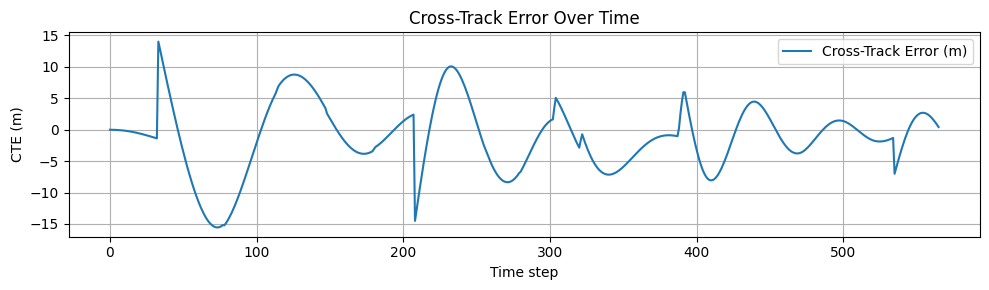

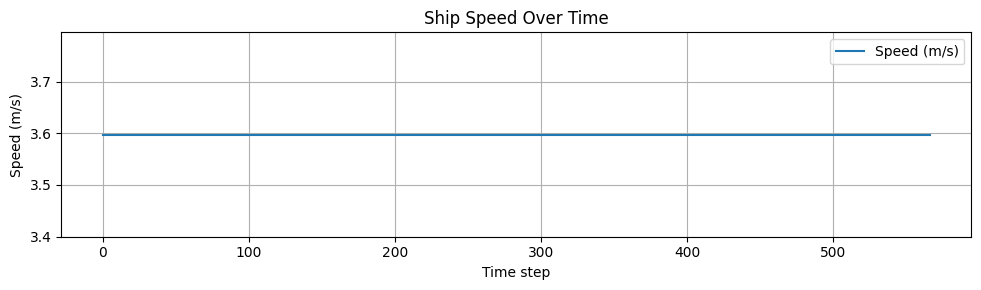

Final Heading: 161.34°
-0.0032741132066997783


In [85]:
# Reduce the reference path
reduced_path = simulation_path[::1]
print(reduced_path[0])  # Every alternate point

initial_heading_deg = (90-calculate_bearing([START_LATLON[0],START_LATLON[1]], reduced_path[1])) % 360
print(calculate_bearing([START_LATLON[0],START_LATLON[1]], reduced_path[1]))
print(reduced_path[1])
print(f"Initial heading: {initial_heading_deg:.2f}°")

# Initialize parameters
params = ShipParameters(START_LATLON[0],START_LATLON[1], initial_heading_deg)

# Run simulation
x_traj, y_traj, final_params, log_data = simulate_motion(params, reduced_path, END_LATLON[0], END_LATLON[1])



# Print final result
"""print(f"Final Position: ({final_params.x:.6f}, {final_params.y:.6f})")
print(f"Final Speed: {final_params.u:.2f} m/s")"""
print(f"Final Heading: {np.degrees(final_params.psi)%360:.2f}°")
print(final_params.r)

### Ploting the position using Folium

In [86]:
# 1. Define start location for map center
start_location = [x_traj[0], y_traj[0]]
m = folium.Map(location=start_location, zoom_start=14)

# 2. Create trajectory path (ship motion path)
trajectory = list(zip(x_traj, y_traj))

# 3. Add simulated trajectory to map
folium.PolyLine(
    locations=trajectory,
    color="blue",
    weight=3,
    opacity=0.7,
    tooltip="Simulated Ship Path"
).add_to(m)

# 4. Add start and end markers for trajectory
folium.Marker(location=trajectory[0], popup="Start", icon=folium.Icon(color='green')).add_to(m)
folium.Marker(location=trajectory[-1], popup="End", icon=folium.Icon(color='red')).add_to(m)

# 5. Add reference path (simulation_path)
folium.PolyLine(
    locations=simulation_path,
    color="purple",
    weight=2,
    opacity=0.7,
    tooltip="Reference Path (simulation_path)"
).add_to(m)

# 6. Optionally: add marker at each reference point
for idx, point in enumerate(simulation_path):
    folium.CircleMarker(
        location=point,
        radius=2,
        color="purple",
        fill=True,
        fill_opacity=0.7,
        popup=f"Ref {idx}"
    ).add_to(m)

# 7. Display the map
m

In [87]:
for step in sorted(log_data):
    if step % 500 == 0:
        print(f"Step {step}:", log_data[step])
    if step == 1:
        print(f"Step {step}:", log_data[step])



Step 1: {'timestamp': 0, 'latitude': 49.012671205073396, 'longitude': 8.341216925644648, 'x_velocity': -1.6563670007566522, 'y_velocity': 1.1159677526976923, 'heading': 146.05812471649705}
Step 500: {'timestamp': 499, 'latitude': 49.01595226975385, 'longitude': 8.323242861087982, 'x_velocity': -3.5280757978619124, 'y_velocity': 0.19642568113647296, 'heading': 177.8283358203482}


In [88]:
import json

# Save to JSON file
with open("log_data.json", "w") as f:
    json.dump(log_data, f, indent=4)  # indent=4 for readability
